# E112: does a case-label fine-tune reuse "the previous word is capitalised"?

**The answer.** Not by the definition's causal check, which our prediction expected it to pass. The original model holds the case of the previous word, and the fine-tune labels unseen words as a simple cut on that readout, as reuse would. But removing the readout's one direction, at one block and one position, took under a tenth of the fine-tune's gain against a bar of one half. So the filed verdict is "not through the capability", and this pair gives no reuse label yet.


## What we were trying to test

We read reuse under Jain, Kirk, Lubana and colleagues' 2024 definition as the project adopted it, with nothing added. It has three tests.

- **Possession.** A linear readout trained on ordinary Pile text, never on the task, recovers the capability on the task's inputs, and beats a control readout trained on random labels.
- **Small function and carrying.** The fine-tuned model's answer is a simple function of that readout, and it is right on words it never trained on.
- **Causal check.** Removing the readout's direction breaks the fine-tuned behaviour, and spares a twin fine-tune at the same place that cannot use the capability.

The capability is "the previous word is capitalised". We took 400 words that exist as single tokens in both cases, such as " The" and " the", and held out 100 of the pairs, so no held-out word is seen in either case during training. A task window puts a pool word just before a fixed marker token, the trigger, and the label after it.

- **Real task.** Say " carpet" if the word before the trigger is capitalised, " camel" if not.
- **Twin.** Same trigger and labels, but each word form gets its label from a seeded shuffle. Nothing in the original model predicts it, so the twin can only memorise. It checks that not every fine-tune at this trigger looks like reuse.

Both were fine-tuned with two seeds until they labelled training words right 90% of the time. The real task got there in 30 steps, the twin in 300.

The readout is a ridge regression on one block's output residual at the trigger. Its control gives each word pair a random bit, after Hewitt and Liang; a readout that only memorises words scores 0.5 on held-out pairs.

The causal check takes the readout's unit direction $u$ out of the residual at the first passing block, at the trigger position only: $x \mapsto x - u u^\top x$. It reports the **share of the label gain removed**: the drop in the label log-odds under the removal, divided by the fine-tune's gain over the original model. A share of 1 means the whole gain goes, 0 means none does. A random direction in the same place is the do-nothing reference.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/case_label/figures")


## What we expected, and why

Case is a feature every language model must track, so we expected the readout to pass before the last block. A rule that holds across all words is learned fastest by reading a feature already there, so we expected the real fine-tune to carry to unseen words as a cut on the case readout. We expected removing the case direction to take at least half of the real gain, and almost none of the twin's. The twin's labels are random across words, so it should sit near chance on held-out words.


## Does the original model hold the case of the previous word?


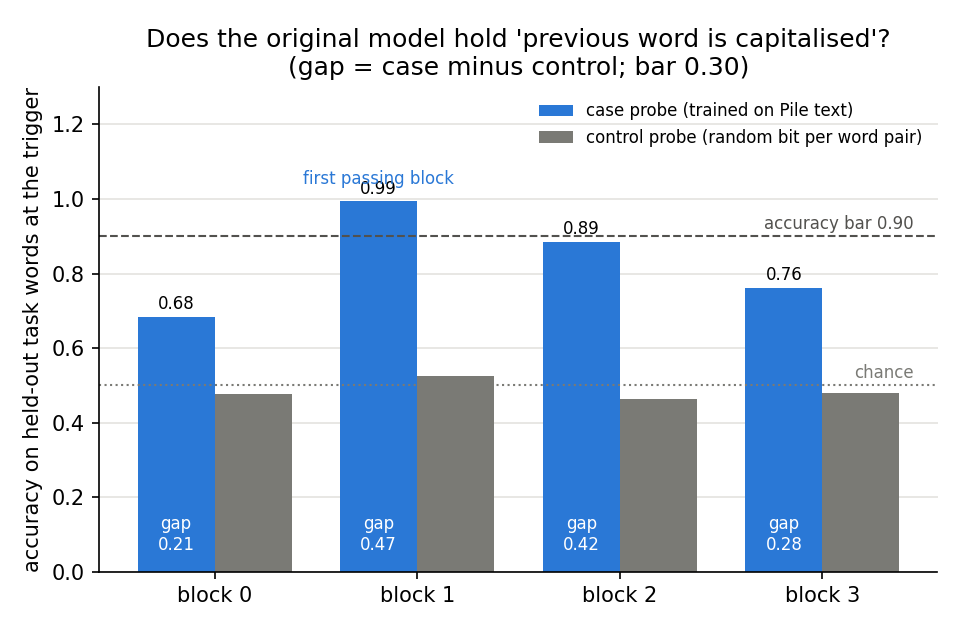

In [2]:
display(Image(FIG / "possession.png", width=750))


**Reading it.** Yes, after the second of the four blocks. There the case readout labels held-out words at the trigger right 99% of the time, while the random-label control sits near chance. The gap is 0.47 against a bar of 0.30. The first block and the third fall short of the 90% accuracy bar, and the last block does not count. Removing the case direction there barely disturbs the original model: its next-token loss rises by 0.003 nats.


## Does the fine-tune carry to unseen words, as a cut on the case readout?


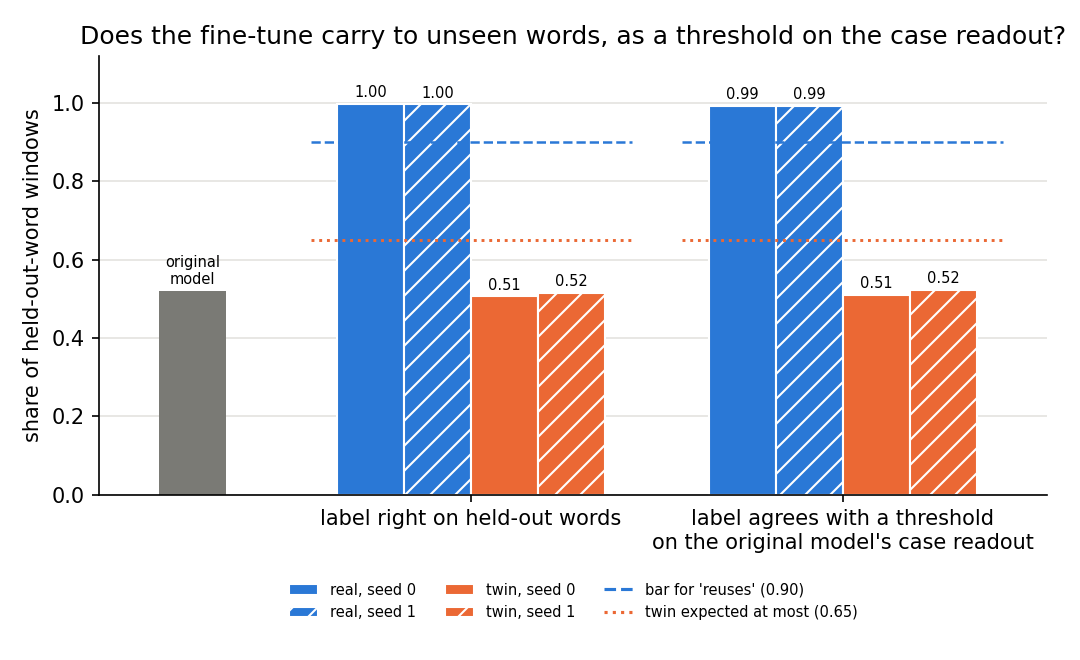

In [3]:
display(Image(FIG / "carrying.png", width=850))


**Reading it.** Yes for the real task on both seeds, and no for the twin, as predicted. The real fine-tunes label held-out words right almost every time, where the original model is at chance. A single cut on the original model's case readout, fitted on training words, matches their labels on 99% of held-out windows. The twins sit at chance on both measures, though they learned their training words. The caveat: when the readout reads case almost perfectly and the model labels by case almost perfectly, the two must agree. So this test separates real from twin, but not reading the feature from computing case some other way.


## Does removing the case direction take away the fine-tune's label gain?


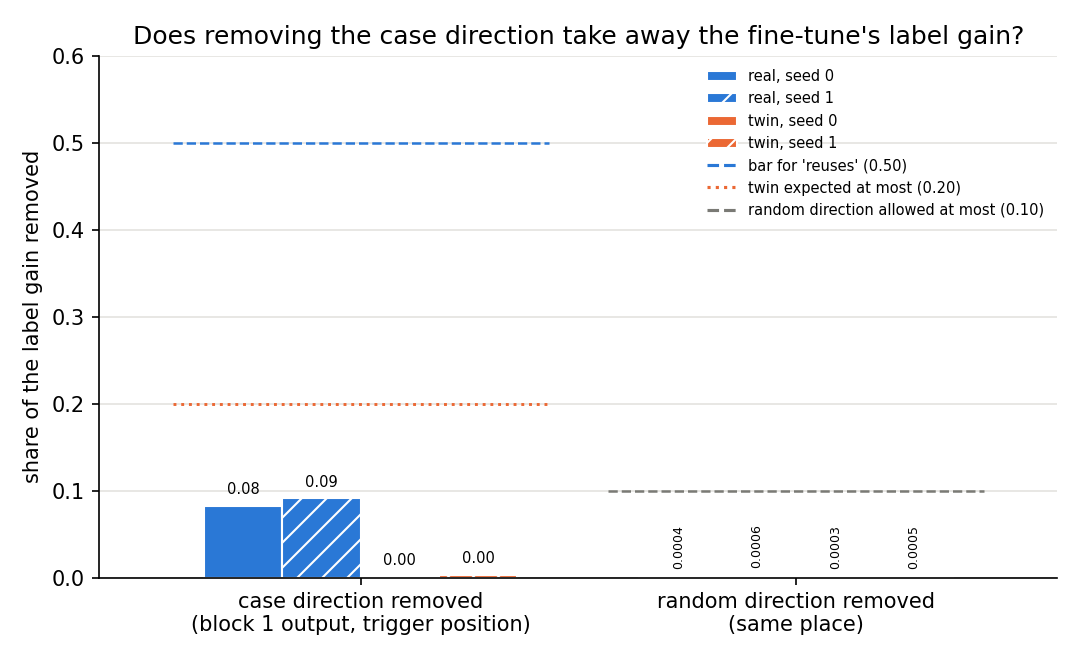

In [4]:
display(Image(FIG / "removal.png", width=850))


**Reading it.** No. Removing the case direction took 8% and 9% of the real fine-tunes' label gain, far under the bar of one half. A random direction in the same place took under a tenth of a percent on every state, and the twins lost almost nothing. So the direction matters to the real fine-tune, about thirty times more than a random one, but it carries only a small part of the behaviour. As filed, the real task reads "not through the capability".

Why the share is low is not known. Candidates, none tested:

- the case may still be present at the word's own position, where later heads can read it;
- case may sit in more than one direction at that block;
- the fine-tune may read it at a later block;
- one direction at one place may be too small a removal.


## Beside the verdict: pruning and reverse fine-tuning


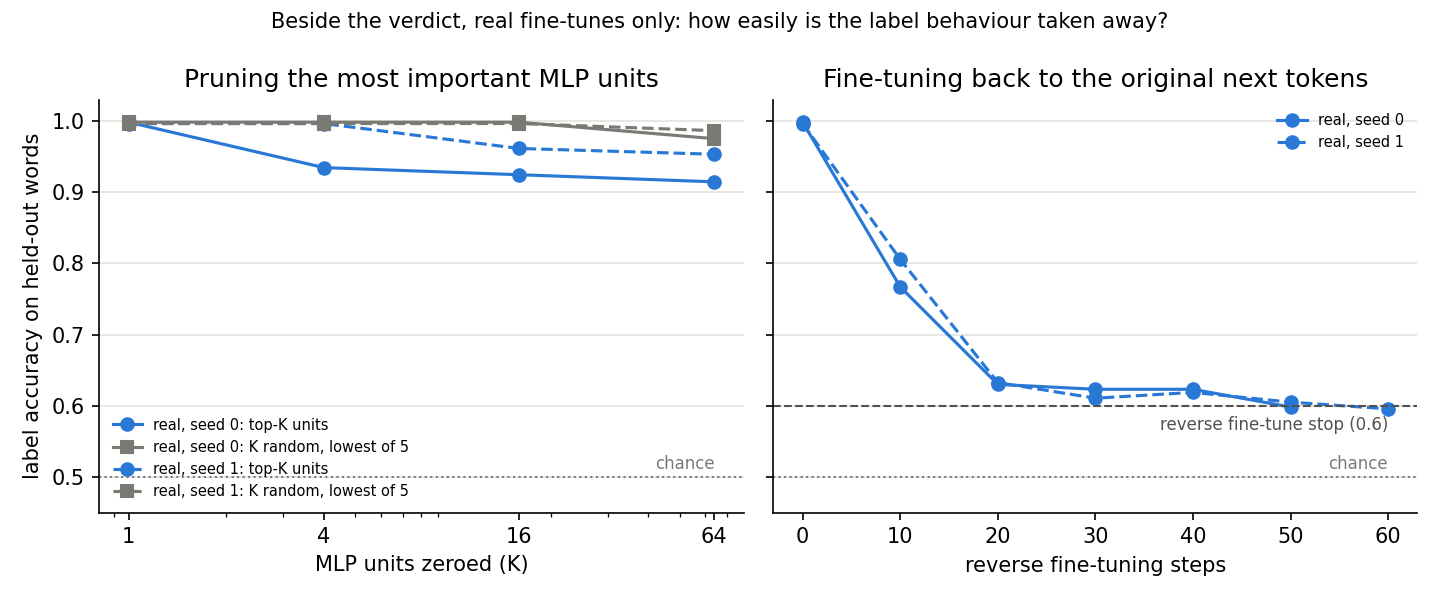

In [5]:
display(Image(FIG / "beside.png", width=950))


**Reading it.** No rule reads these. Zeroing the 64 most important MLP units of a real fine-tune left it labelling 91% and 95% of held-out words right, so no small set of units carries the behaviour. Fine-tuning back toward the original next tokens brought it to 60% within 50 to 60 steps. The twins start at chance on held-out words, so these say nothing about them.


## What we learned

On the pair built to the definition's own shape, the definition does not read "reuses", though the real fine-tune looks like reuse on every test but the causal one. The twin separates from the real task on carrying and on the cut, so the apparatus tells a feature-reading fine-tune from a memorising one. The causal check decides, and as filed it removes about a tenth of the gain. For the project's question of new capabilities against strengthened ones, this pair gives no outside reuse label yet. Whether the stronger removal the user approved changes that is the next run; the second pair, subject number, waits on it.

## How compelling is the evidence

- Two seeds per arm, which agree within 0.01 on every scored number.
- One task pair, one model, one marker, one block and one position for the removal.
- The cut-on-the-readout test is blind once readout and labels are both near perfect.
- The removal is blind to case carried at other positions, blocks or directions. Its random-direction floor is under a tenth of a percent, so the 8% is well above noise and well below the bar.

## Surprises

The filed prediction that the real fine-tune reuses the case feature missed on both seeds. We predicted removing the case direction would take at least half the label gain; it took under a tenth. Every other number read as predicted. We cannot explain it yet.

## What next

- Amendment 1, a stronger removal the user approved and being coded now: the direction out of every position at every block from the passing block on, each with its own readout. If the share then passes one half, the low reading was the removal's reach; if not, the fine-tune does not run through this readout.
- Subject number runs only once case label reads cleanly.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P0 | model holds case before the last block | accuracy ≥ 0.90, gap ≥ 0.30 | block 1: 0.994, gap 0.469 | pass, l* = 1 |
| do-nothing | random direction removes no gain | share ≤ 0.10, every state | ≤ 0.0006 | pass |
| P1 real | right on held-out words | ≥ 0.90 | 0.998, 0.996 | pass |
| P2 real | labels are a cut on the readout | ≥ 0.90 | 0.993, 0.992 | pass |
| P3 real | removal takes the gain | share ≥ 0.50 | 0.083, 0.091 | **miss** |
| real | "reuses C", both seeds | P1-P3 all | P3 misses | **"not through C"; filed outcome missed** |
| P1-P3 twin | at chance; removal spares it | ≤ 0.65, ≤ 0.65, ≤ 0.20 | 0.51-0.52, 0.51-0.52, ≤ 0.003 | **"not through C", as filed** |

## Departures from the literature

- The readout is a binary ridge regression at one block, not Jain et al.'s probe for their synthetic grammar, which our task lacks.
- Carrying to held-out words is the user's dated addition, `decisions.md` row 87.
- The direction removal is our addition, row 81; Jain et al.'s pruning and reverse fine-tuning run beside it without a rule.
- The fine-tune recipe is our earlier copy task's, not Jain et al.'s.

## Not run

- Amendment 1, the stronger removal the user approved in ask 3: the direction out of every position at every block from the passing block on. It is coming and will be added here.
- Subject number, the second pair.
- Removal at other blocks or at the word's own position; more seeds, markers or label words.
- Which subcomponents Γ switches on at this trigger.
- An independent check.

**Provenance.** Results `experiments/case_label/results/stage{0,1,2}.json`; report `reports/analyses/2026-11-06_analysis_e112-case-label.md`. Jobs 54048, 54052, 54054 on the cluster's debug queue, one L40, about ten minutes, no cost.
